# 05 · Prophet compared with LightGBM (KAN-146)

**Question:** is our LightGBM model really better than a well-known "classic" forecasting tool?
**Prophet** (Meta; Taylor & Letham, 2018) is the usual first choice for business time series. It adds up:

`expected use = trend + daily shape + weekly shape + yearly shape + holidays + extra regressors`

Prophet does **not** use the circuit's recent use (no lags). So it is the fair counterpart of our **LightGBM_normal**
(no recent use either), and a strong classic reference for **LightGBM_forecast** (our chosen model, which does use
yesterday's and last week's use).

**Set-up (same protocol as notebook 02, code in `src/prophet_compare.py`)**
* Same 9 circuits, same hours for every model, same split: fit on train → score validation; refit on train + validation
  → score test (used once); refit on everything before 2025 → score 2025.
* Prophet gets the same calendar and weather as LightGBM (holiday, break, August closure, heating and cooling degrees, sun),
  and a separate daily shape for working and non-working days.
* Prophet's trend setting is chosen **on validation only**, from: stiff linear trend, flexible linear trend, or flat (no trend).
* LightGBM uses the settings already chosen in notebook 02 (`reports/model_params.json`); B2 (4-week median) is the reference baseline.
* Metric: MAE in kWh per hour (main), plus NMBE (bias: positive = the model predicts too little).

In [1]:
import json, sys
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from src.data import load, FOCUS, short, FIG
from src.prophet_compare import compare_circuit, PROPHET_GRID

REP = ROOT / "reports"
pd.set_option("display.width", 160, "display.precision", 3)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e6e6e3", "axes.edgecolor": "#8f8e89",
                     "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e"})
MODELS = ["B2_median_4w", "LightGBM_forecast", "LightGBM_normal", "Prophet"]
COL = {"B2_median_4w": "#8f8e89", "LightGBM_forecast": "#2a78d6", "LightGBM_normal": "#1baf7a", "Prophet": "#eb6834"}
def save(fig, name): fig.savefig(FIG / f"prophet_{name}.png", bbox_inches="tight")

df = load()
params = json.load(open(REP / "model_params.json"))
print(f"{len(df):,} hours · Prophet settings tried on validation: {PROPHET_GRID}")

24,911 hours · Prophet settings tried on validation: [{'growth': 'linear', 'changepoint_prior_scale': 0.01}, {'growth': 'linear', 'changepoint_prior_scale': 0.1}, {'growth': 'flat', 'changepoint_prior_scale': 0.05}]


## 1. Fit and score every circuit (≈ 10 minutes: Prophet is slow)

In [2]:
runs = {c: compare_circuit(df, c, params[short(c)]) for c in FOCUS}
R = pd.concat([r["results"] for r in runs.values()], ignore_index=True)
R["circuit"] = R["circuit"].map(short)
chosen = pd.DataFrame({short(c): r["prophet_params"] for c, r in runs.items()}).T
print("Prophet setting chosen on validation:"); display(chosen)

Importing plotly failed. Interactive plots will not work.


/usr/local/lib/python3.13/dist-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


15:30:02 - cmdstanpy - INFO - Chain [1] start processing


15:30:06 - cmdstanpy - INFO - Chain [1] done processing


15:30:08 - cmdstanpy - INFO - Chain [1] start processing


15:30:15 - cmdstanpy - INFO - Chain [1] done processing


... (102 outputs left out)

15:35:34 - cmdstanpy - INFO - Chain [1] start processing


15:35:36 - cmdstanpy - INFO - Chain [1] done processing


Prophet setting chosen on validation:


,growth,changepoint_prior_scale
NW Plugs & Sockets,flat,0.05
SW Plugs & Sockets,flat,0.05
SE Plugs & Sockets,linear,0.01
NE Plugs & Sockets,flat,0.05
NW Lighting,linear,0.1
SW Lighting,linear,0.01
SE Lighting,linear,0.1
NW HVAC,linear,0.1
SE HVAC,linear,0.01


**Sanity check:** LightGBM_forecast must give the same test MAE as in notebook 02 (same hours, same settings).

In [3]:
nb02 = pd.read_csv(REP / "model_comparison.csv").query("period == 'test' and model == 'LightGBM_forecast'")
nb02 = nb02.set_index(nb02["circuit"].map(short))["MAE_kWh"]
here = R.query("period == 'test' and model == 'LightGBM_forecast'").set_index("circuit")["MAE_kWh"]
check = pd.DataFrame({"notebook 02": nb02, "here": here}); check["same"] = (check.diff(axis=1)["here"].abs() < 1e-6)
display(check.round(4))

,notebook 02,here,same
circuit,,,
NW Plugs & Sockets,0.974,0.974,True
SW Plugs & Sockets,0.088,0.088,True
SE Plugs & Sockets,0.062,0.062,True
NE Plugs & Sockets,0.036,0.036,True
NW Lighting,0.080,0.080,True
SW Lighting,0.208,0.208,True
SE Lighting,0.091,0.091,True
NW HVAC,0.060,0.060,True
SE HVAC,0.036,0.036,True


## 2. Results, MAE in kWh per hour (lower is better)

In [4]:
for period, title in [("val", "Validation (Sep – Dec 2022)"), ("test", "Test (Jan – Feb 2023, used once)"),
                      ("regime_b", "2025 out-of-time check")]:
    t = R[R.period == period].pivot(index="circuit", columns="model", values="MAE_kWh")[MODELS]
    t["best"] = t.idxmin(axis=1)
    print(title); display(t.round(3))

avg = R.groupby(["period", "model"])["MAE_kWh"].mean().unstack()[MODELS].reindex(["val", "test", "regime_b"])
print("Average MAE over the 9 circuits:"); display(avg.round(3))
wins = (R.pivot_table(index=["period", "circuit"], columns="model", values="MAE_kWh")[MODELS]
          .idxmin(axis=1).groupby(level=0).value_counts().unstack(fill_value=0).reindex(columns=MODELS, fill_value=0))
print("Number of circuits where each model is best:"); display(wins)

Validation (Sep – Dec 2022)


model,B2_median_4w,LightGBM_forecast,LightGBM_normal,Prophet,best
circuit,,,,,
NE Plugs & Sockets,0.069,0.028,0.071,0.077,LightGBM_forecast
NW HVAC,0.002,0.004,0.021,0.031,B2_median_4w
NW Lighting,0.107,0.065,0.129,0.117,LightGBM_forecast
NW Plugs & Sockets,0.847,0.694,0.849,0.924,LightGBM_forecast
SE HVAC,0.014,0.013,0.016,0.017,LightGBM_forecast
SE Lighting,0.121,0.106,0.108,0.108,LightGBM_forecast
SE Plugs & Sockets,0.054,0.078,0.129,0.113,B2_median_4w
SW Lighting,0.210,0.172,0.170,0.185,LightGBM_normal
SW Plugs & Sockets,0.078,0.058,0.082,0.078,LightGBM_forecast


Test (Jan – Feb 2023, used once)


model,B2_median_4w,LightGBM_forecast,LightGBM_normal,Prophet,best
circuit,,,,,
NE Plugs & Sockets,0.076,0.037,0.057,0.054,LightGBM_forecast
NW HVAC,0.113,0.060,0.090,0.147,LightGBM_forecast
NW Lighting,0.092,0.080,0.103,0.111,LightGBM_forecast
NW Plugs & Sockets,1.051,0.974,1.170,1.266,LightGBM_forecast
SE HVAC,0.035,0.036,0.041,0.039,B2_median_4w
SE Lighting,0.084,0.092,0.097,0.125,B2_median_4w
SE Plugs & Sockets,0.059,0.062,0.070,0.162,B2_median_4w
SW Lighting,0.206,0.209,0.216,0.293,B2_median_4w
SW Plugs & Sockets,0.160,0.088,0.138,0.135,LightGBM_forecast


2025 out-of-time check


model,B2_median_4w,LightGBM_forecast,LightGBM_normal,Prophet,best
circuit,,,,,
NE Plugs & Sockets,0.006,0.005,0.044,0.008,LightGBM_forecast
NW HVAC,0.072,0.055,0.061,0.778,LightGBM_forecast
NW Lighting,0.039,0.041,0.108,0.059,B2_median_4w
NW Plugs & Sockets,0.197,0.177,0.198,0.387,LightGBM_forecast
SE HVAC,0.008,0.018,0.023,0.082,B2_median_4w
SE Lighting,0.111,0.053,0.046,0.394,LightGBM_normal
SE Plugs & Sockets,0.056,0.050,0.058,0.110,LightGBM_forecast
SW Lighting,0.025,0.016,0.039,1.236,LightGBM_forecast
SW Plugs & Sockets,0.034,0.039,0.098,0.127,B2_median_4w


Average MAE over the 9 circuits:


model,B2_median_4w,LightGBM_forecast,LightGBM_normal,Prophet
period,,,,
val,0.167,0.135,0.175,0.183
test,0.208,0.182,0.220,0.259
regime_b,0.061,0.051,0.075,0.354


Number of circuits where each model is best:


,B2_median_4w,LightGBM_forecast,LightGBM_normal,Prophet
period,,,,
regime_b,3,5,1,0
test,4,5,0,0
val,2,6,1,0


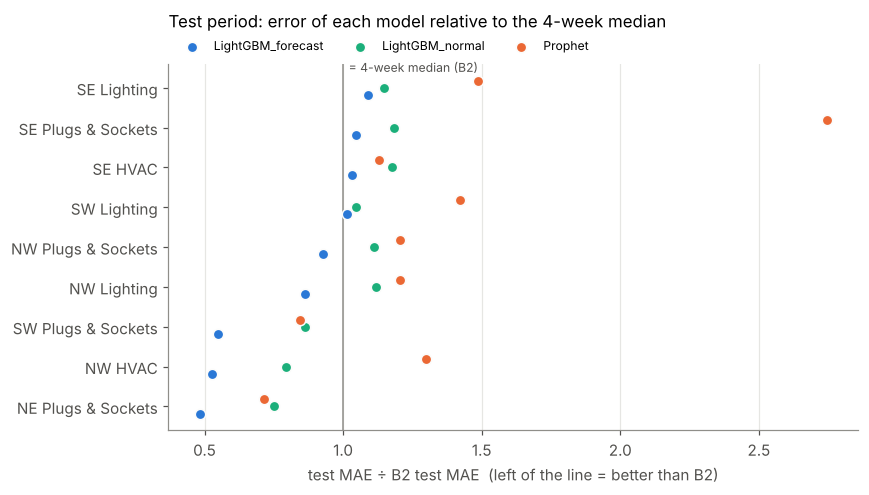

In [5]:
rel = R[R.period == "test"].pivot(index="circuit", columns="model", values="MAE_kWh")[MODELS]
rel = rel.div(rel["B2_median_4w"], axis=0)                  # 1 = as good as the 4-week median
rel = rel.loc[rel["LightGBM_forecast"].sort_values().index]
fig, ax = plt.subplots(figsize=(8, 4.6))
y = np.arange(len(rel))
ax.axvline(1, color="#8f8e89", lw=1)
ax.text(1.02, len(rel) - 0.6, "= 4-week median (B2)", fontsize=8, color="#52514e")
for i, mth in enumerate(["LightGBM_forecast", "LightGBM_normal", "Prophet"]):
    ax.scatter(rel[mth], y + (i - 1) * 0.18, s=46, color=COL[mth], label=mth, zorder=3, edgecolor="#fcfcfb", lw=1)
ax.set_yticks(y, rel.index); ax.set_xlabel("test MAE ÷ B2 test MAE  (left of the line = better than B2)")
ax.set_title("Test period: error of each model relative to the 4-week median", loc="left", fontsize=11, pad=24)
ax.legend(frameon=False, fontsize=8, ncol=3, loc="lower left", bbox_to_anchor=(0, 1.0)); ax.grid(axis="y", visible=False)
fig.tight_layout(); save(fig, "01_relative_mae_test"); plt.show()

## 3. What the difference looks like: one test week of NW Plugs & Sockets

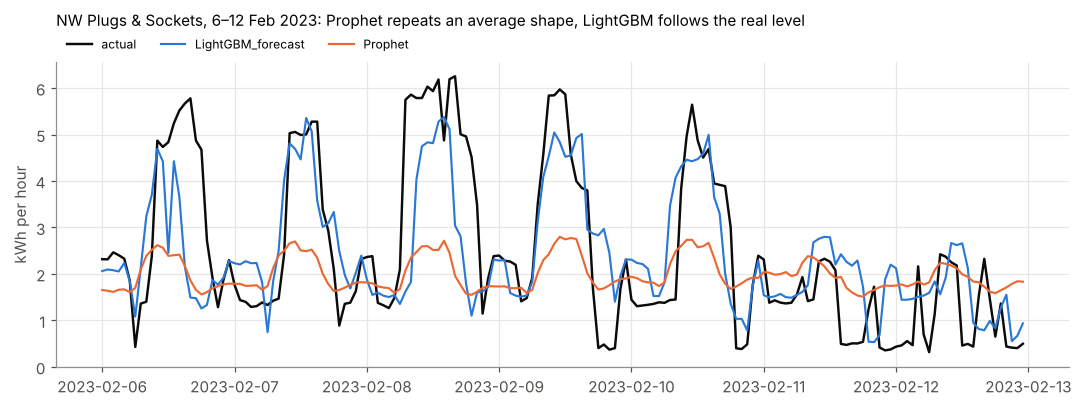

In [6]:
P = runs["NW|Plugs & Sockets W"]["predictions"]["test"].set_index("timestamp_local") / 1000
P = P.reindex(pd.date_range("2023-02-06", "2023-02-12 23:00", freq="h"))     # missing hours stay empty
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(P.index, P["actual"], color="#0b0b0b", lw=1.6, label="actual")
ax.plot(P.index, P["LightGBM_forecast"], color=COL["LightGBM_forecast"], lw=1.4, label="LightGBM_forecast")
ax.plot(P.index, P["Prophet"], color=COL["Prophet"], lw=1.4, label="Prophet")
ax.set_ylabel("kWh per hour"); ax.set_ylim(bottom=0)
ax.set_title("NW Plugs & Sockets, 6–12 Feb 2023: Prophet repeats an average shape, LightGBM follows the real level",
             loc="left", fontsize=10, pad=24)
ax.legend(frameon=False, fontsize=8, ncol=3, loc="lower left", bbox_to_anchor=(0, 1.0))
fig.tight_layout(); save(fig, "02_week_NW_plugs"); plt.show()

## 4. Why Prophet fails on 2025: the trend
A linear trend learned on 2020 – 2023 is extended over the 2.5-year gap. Bias (NMBE, %) on 2025:

In [7]:
bias = R[R.period == "regime_b"].pivot(index="circuit", columns="model", values="NMBE_%")[MODELS]
display(bias.join(chosen["growth"]).round(1))

,B2_median_4w,LightGBM_forecast,LightGBM_normal,Prophet,growth
circuit,,,,,
NE Plugs & Sockets,-0.5,-1.7,21.7,-1.8,flat
NW HVAC,-7.5,6.3,55.0,-848.5,linear
NW Lighting,25.8,6.8,-128.7,100.0,linear
NW Plugs & Sockets,18.5,15.3,18.3,4.9,flat
SE HVAC,-1.3,-35.7,-46.9,-227.1,linear
SE Lighting,-54.5,72.4,99.8,-834.3,linear
SE Plugs & Sockets,-23.4,-5.8,25.1,-91.1,linear
SW Lighting,-37.0,82.0,-116.2,-7666.3,linear
SW Plugs & Sockets,-6.4,-18.4,-59.8,-78.1,flat


## 5. Save

In [8]:
R.to_csv(REP / "prophet_comparison.csv", index=False)
print("saved reports/prophet_comparison.csv", R.shape)

saved reports/prophet_comparison.csv (108, 8)


## 6. Conclusions

* **LightGBM_forecast stays the model.** On test it is best on 5 of 9 circuits; on the others the simple 4-week median
  (B2) is best, never Prophet. Average test MAE: LightGBM_forecast 0.182 · B2 0.208 · LightGBM_normal 0.220 · Prophet 0.259 kWh.
* **Prophet is not better than our simplest baseline.** It is best on no circuit in any period. It describes an
  *average* week well, but it cannot follow the real level of the last days (a heater switched on for a cold week),
  because it has no memory of recent use. That memory (`lag_24`, ≈ 45 % of LightGBM's gain) is what makes the difference.
* **Against the fair counterpart** (LightGBM_normal, also without recent use), Prophet is a little worse on validation
  (0.183 vs 0.175 kWh), clearly worse on test (0.259 vs 0.220) and much worse on 2025 (0.354 vs 0.075).
* **Prophet breaks on 2025.** Where validation chose a linear trend, the slope is extended over 2.5 years without data
  (e.g. SW Lighting, NW HVAC). This is a real risk for a live system and a strong argument for a model that re-anchors on
  recent data.
* **Limits:** a small Prophet grid (3 trend settings), no hyper-parameter search on the seasonalities; SARIMA was not tried
  (one model per circuit with hourly data and a 2.5-year gap would need much more care). The conclusion is unlikely to change:
  even B2 beats Prophet on most circuits.